# Financial Sentiment Analysis: Multi-Model Comparison (Groq LLMs)

## 📌 Project Overview
This Jupyter Notebook provides an extended, multi-model evaluation pipeline for financial sentiment analysis using the benchmark **Financial PhraseBank** dataset. It systematically compares three distinct model configurations accessed via the Groq API:
1. **`openai/gpt-oss-120b`**: High-capacity open-weight baseline model.
2. **`qwen/qwen3.8-27b`**: Mid-scale efficient transformer architecture.
3. **`openai/gpt-oss-20b`**: Lightweight efficient parameter model.

The notebook evaluates each model across Zero-Shot and Few-Shot prompting paradigms.

---

## **Cell 0: Environment Setup & Dependency Installation**
> **Note:** Run this cell once to install necessary packages (such as `groq`, `scikit-learn`, `seaborn`, and `kagglehub`) if they are missing in your environment.

In [1]:
# Install core libraries for API interaction, data manipulation, and visualization
# %pip -q install groq scikit-learn pandas numpy matplotlib seaborn kagglehub

## **Cell 1: Import Libraries and Configuration**
Import essential Python modules for regex processing, timing, data handling, visualization, dataset downloading, and machine learning metric evaluation.

In [14]:
import os
import re
import time
import warnings
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import kagglehub

from google.colab import userdata
from groq import Groq, RateLimitError

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, precision_recall_fscore_support, classification_report, confusion_matrix
from transformers import AutoTokenizer, AutoModelForSequenceClassification, pipeline

warnings.filterwarnings('ignore')

## **Cell 2: Download and Load the Dataset**
Downloads the Financial PhraseBank dataset via Kaggle Hub, loads the CSV file, removes duplicate entries, and normalizes sentiment labels.

In [3]:
path = kagglehub.dataset_download("ankurzing/sentiment-analysis-for-financial-news")
csv_path = os.path.join(path, "all-data.csv")

df = pd.read_csv(csv_path, encoding='latin-1', header=None, names=['Sentiment', 'News Headline'])
df = df.drop_duplicates().reset_index(drop=True)
df['Sentiment'] = df['Sentiment'].str.strip().str.lower()
print(f"Dataset Shape: {df.shape}")
df.head()

100%|██████████| 903k/903k [00:00<00:00, 90.2MB/s]

Extracting files...
Dataset Shape: (4840, 2)


,Sentiment,News Headline
0,neutral,"According to Gran , the company has no plans t..."
1,neutral,Technopolis plans to develop in stages an area...
2,negative,The international electronic industry company ...
3,positive,With the new production plant the company woul...
4,positive,According to the company 's updated strategy f...


## **Cell 3: Train/Test Stratified Split (80% Train, 20% Test)**
Performs a stratified split to ensure proportional class distribution (positive, neutral, negative) across training and testing subsets.

In [4]:
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df['Sentiment']
)

print(f"Training set shape: {train_df.shape}")
print(f"Test set shape: {test_df.shape}")

Training set shape: (3872, 2)
Test set shape: (968, 2)


## **Cell 4: Sentiment Distribution Visualization (`matplotlib.pyplot`)**
Generates a bar chart illustrating the class imbalance/distribution across sentiment categories in the test dataset.

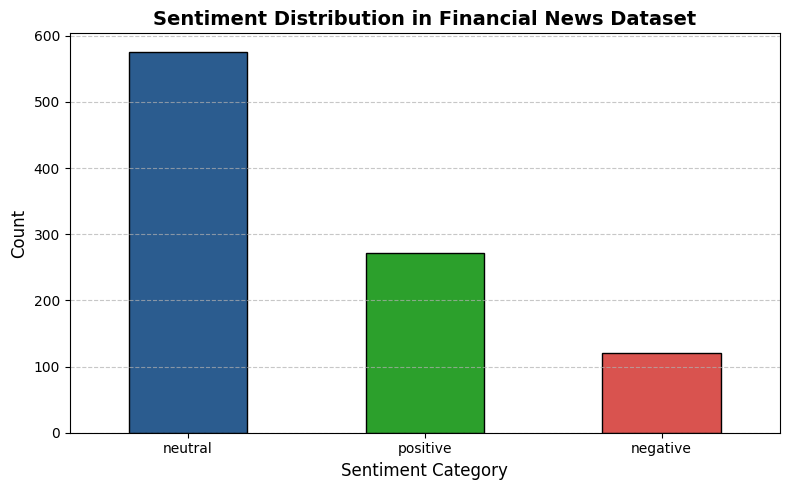

In [11]:
sentiment_counts = test_df['Sentiment'].value_counts()

plt.figure(figsize=(8, 5))
sentiment_counts.plot(kind='bar', color=['#2b5c8f', '#2ca02c', '#d9534f'], edgecolor='black')
plt.title('Sentiment Distribution in Financial News Dataset', fontsize=14, fontweight='bold')
plt.xlabel('Sentiment Category', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(rotation=0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

## **Cell 5: Multi-Model Initialization & Evaluation Harness**
Defines the Groq LLM models list (`openai/gpt-oss-120b`, `qwen/qwen3.8-27b`, `openai/gpt-oss-20b`) and sets up FinBERT (`ProsusAI/finbert`) which is pre-trained on a financial corpus and further fine-tuned on the Financial PhraseBank dataset for sentiment classification.

In [5]:
groq_api_key = userdata.get('GROQ_API_KEY')
client = Groq(api_key=groq_api_key)

# List of target models to evaluate
MODELS = [
    "openai/gpt-oss-120b",
    "qwen/qwen3.8-27b",
    "openai/gpt-oss-20b"
]

def safe_chat_completion(client, messages, model, temperature=0.0, max_retries=3):
    """Wraps Groq API calls with automatic retry handling and backoff on rate limits."""
    for attempt in range(max_retries):
        try:
            response = client.chat.completions.create(
                messages=messages,
                model=model,
                temperature=temperature
            )
            time.sleep(0.5)
            return response
        except RateLimitError as e:
            if attempt == max_retries - 1:
                raise e
            wait_time = (2 ** attempt) + 1
            print(f"[{model}] Rate limit hit. Retrying in {wait_time} seconds...")
            time.sleep(wait_time)
        except Exception as e:
            raise e

def evaluate_configuration(model_id, config_name, y_true, y_pred):
    accuracy = accuracy_score(y_true, y_pred)
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='weighted', zero_division=0
    )
    return {
        "Model": model_id,
        "Configuration": config_name,
        "Accuracy": round(accuracy, 2),
        "Precision": round(precision, 2),
        "Recall": round(recall, 2),
        "F1-score": round(f1, 2)
    }

## **Cell 6: Multi-Model Zero-Shot & Few-Shot Evaluation Execution**

In [6]:
test_samples = test_df.sample(n=40, random_state=42).reset_index(drop=True)
true_labels = test_samples['Sentiment'].tolist()

system_prompt = (
    "The goal is to classify financial texts (e.g., news articles, analyst reports, or company announcements) "
    "into three categories: positive, negative, or neutral sentiment. "
    "These sentiment categories are used to predict how the market might react to the financial information presented in the text."
)

# Prepare Few-Shot examples
pos_ex = df[df["Sentiment"] == "positive"].sample(3, random_state=42)
neg_ex = df[df["Sentiment"] == "negative"].sample(3, random_state=42)
neu_ex = df[df["Sentiment"] == "neutral"].sample(3, random_state=42)
few_shot_df = pd.concat([pos_ex, neg_ex, neu_ex]).reset_index(drop=True)

formatted_examples = []
for i, row in few_shot_df.iterrows():
    formatted_examples.append(f'S{i+1}: "{row["News Headline"]}" -> {row["Sentiment"]}')
few_shot_examples_text = "\n".join(formatted_examples)

all_results = []
model_predictions = {}

for model_id in MODELS:
    print(f"\n================ Evaluating Model: {model_id} ================")

    # 1. Zero-Shot
    print(f"--- Running Zero-Shot ---")
    zs_preds = []
    for idx, row in test_samples.iterrows():
        text_input = row['News Headline']
        zero_shot_prompt = (
            f"Please classify the following sentence into exactly one sentiment category "
            f"(positive, negative, or neutral). Return only the category name:\n\n\"{text_input}\""
        )
        try:
            resp = safe_chat_completion(
                client=client,
                messages=[
                    {"role": "system", "content": system_prompt},
                    {"role": "user", "content": zero_shot_prompt}
                ],
                model=model_id,
                temperature=0.0
            )
            pred = resp.choices[0].message.content.strip().lower()
        except Exception as e:
            pred = "neutral"
        zs_preds.append(pred)

    model_predictions[f"{model_id}_zs"] = zs_preds
    all_results.append(evaluate_configuration(model_id, "Zero-shot", true_labels, zs_preds))

    # 2. Few-Shot
    print(f"--- Running Few-Shot ---")
    fs_preds = []
    for idx, row in test_samples.iterrows():
        text_input = row['News Headline']
        few_shot_messages = [
            {"role": "system", "content": "Here are some example demonstrations for sentiment classification. " + system_prompt},
            {"role": "user", "content": "Here are 9 training examples:\n" + few_shot_examples_text},
            {"role": "assistant", "content": "Understood. I will classify subsequent texts into positive, negative, or neutral."},
            {"role": "user", "content": f"Classify the sentiment of this text (return only positive, negative, or neutral): \"{text_input}\""}
        ]
        try:
            resp = safe_chat_completion(
                client=client,
                messages=few_shot_messages,
                model=model_id,
                temperature=0.0
            )
            pred = resp.choices[0].message.content.strip().lower()
        except Exception as e:
            pred = "neutral"
        fs_preds.append(pred)

    model_predictions[f"{model_id}_fs"] = fs_preds
    all_results.append(evaluate_configuration(model_id, "Few-shot", true_labels, fs_preds))

print("\nEvaluation completed across all models!")


================ Evaluating Model: openai/gpt-oss-120b ================
--- Running Zero-Shot ---
--- Running Few-Shot ---

================ Evaluating Model: qwen/qwen3.8-27b ================
--- Running Zero-Shot ---
--- Running Few-Shot ---

================ Evaluating Model: openai/gpt-oss-20b ================
--- Running Zero-Shot ---
--- Running Few-Shot ---

Evaluation completed across all models!


## **Cell 7: FinBERT Evaluation (Fine-Tuned Domain-Specific Transformer)**
Evaluates the `ProsusAI/finbert` model. FinBERT is pre-trained on a financial corpus and further fine-tuned on the Financial PhraseBank dataset for sentiment classification.

In [15]:
print("\n================ Evaluating FinBERT (Fine-Tuned) ================")
finbert_pipeline = pipeline("sentiment-analysis", model="ProsusAI/finbert", tokenizer="ProsusAI/finbert")

finbert_preds = []
for text in test_samples["News Headline"]:
    try:
        res = finbert_pipeline(text[:512])[0]  # truncate to max token length
        label = res['label'].strip().lower() # positive, negative, neutral
    except Exception as e:
        label = "neutral"
    finbert_preds.append(label)

model_predictions["FinBERT_Fine-Tuned"] = finbert_preds
all_results.append(evaluate_configuration("ProsusAI/finbert", "Fine-Tuned", true_labels, finbert_preds))
print("FinBERT evaluation completed!")


================ Evaluating FinBERT (Fine-Tuned) ================


config.json:   0%|          | 0.00/758 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  438MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/252 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

FinBERT evaluation completed!


## **Cell 7: Comparative Performance Summary Table**
Computes overall performance benchmarks and displays a comparative summary dataframe.

In [16]:
summary_df = pd.DataFrame(all_results)
print(
    "\nTABLE: MULTI-MODEL COMPARATIVE RESULTS (LLMs + FINBERT) ON FINANCIAL NEWS DATASET"
)
print("=" * 75)
print(summary_df.to_string(index=False))
print("=" * 75)


TABLE: MULTI-MODEL COMPARATIVE RESULTS (LLMs + FINBERT) ON FINANCIAL NEWS DATASET
              Model Configuration  Accuracy  Precision  Recall  F1-score
openai/gpt-oss-120b     Zero-shot      0.75       0.79    0.75      0.75
openai/gpt-oss-120b      Few-shot      0.80       0.84    0.80      0.80
   qwen/qwen3.8-27b     Zero-shot      0.82       0.85    0.82      0.83
   qwen/qwen3.8-27b      Few-shot      0.82       0.87    0.82      0.83
 openai/gpt-oss-20b     Zero-shot      0.78       0.78    0.78      0.77
 openai/gpt-oss-20b      Few-shot      0.80       0.84    0.80      0.80
   ProsusAI/finbert    Fine-Tuned      0.85       0.88    0.85      0.85


## **Cell 8: Export Predictions DataFrame**
Exports ground truth labels, news headlines, and predictions across all evaluated LLM configurations and FinBERT to a CSV file for reporting.

In [17]:
output_df = pd.DataFrame({
    "true_sentiment": true_labels,
    "news_headline": test_samples["News Headline"].tolist()
})

for key, preds in model_predictions.items():
    output_df[f"pred_{key.replace('/', '_').replace('-', '_')}"] = preds

output_csv_filename = "multimodel_and_finbert_sentiment_predictions.csv"
output_df.to_csv(output_csv_filename, index=False)
print(f"Predictions successfully exported to '{output_csv_filename}'!")
output_df.head()

Predictions successfully exported to 'multimodel_and_finbert_sentiment_predictions.csv'!


,true_sentiment,news_headline,pred_openai_gpt_oss_120b_zs,pred_openai_gpt_oss_120b_fs,pred_qwen_qwen3.8_27b_zs,pred_qwen_qwen3.8_27b_fs,pred_openai_gpt_oss_20b_zs,pred_openai_gpt_oss_20b_fs,pred_FinBERT_Fine_Tuned
0,negative,Finnish meat company Atria can no longer promi...,negative,negative,negative,negative,negative,negative,neutral
1,neutral,The total number of shares in the company will...,neutral,neutral,neutral,neutral,neutral,neutral,neutral
2,neutral,- The Group - s result before taxes was a los...,negative,negative,negative,negative,negative,negative,negative
3,negative,"In the building and home improvement trade , s...",negative,negative,negative,negative,negative,negative,negative
4,neutral,"Rapala VMC Corporation Rapala , a leading fish...",neutral,neutral,neutral,neutral,neutral,neutral,neutral


## **Cell 9: Confusion Matrix Visualizations**
Generates confusion matrix heatmaps for each evaluated model configuration to visualize per-class performance across positive, negative, and neutral categories.

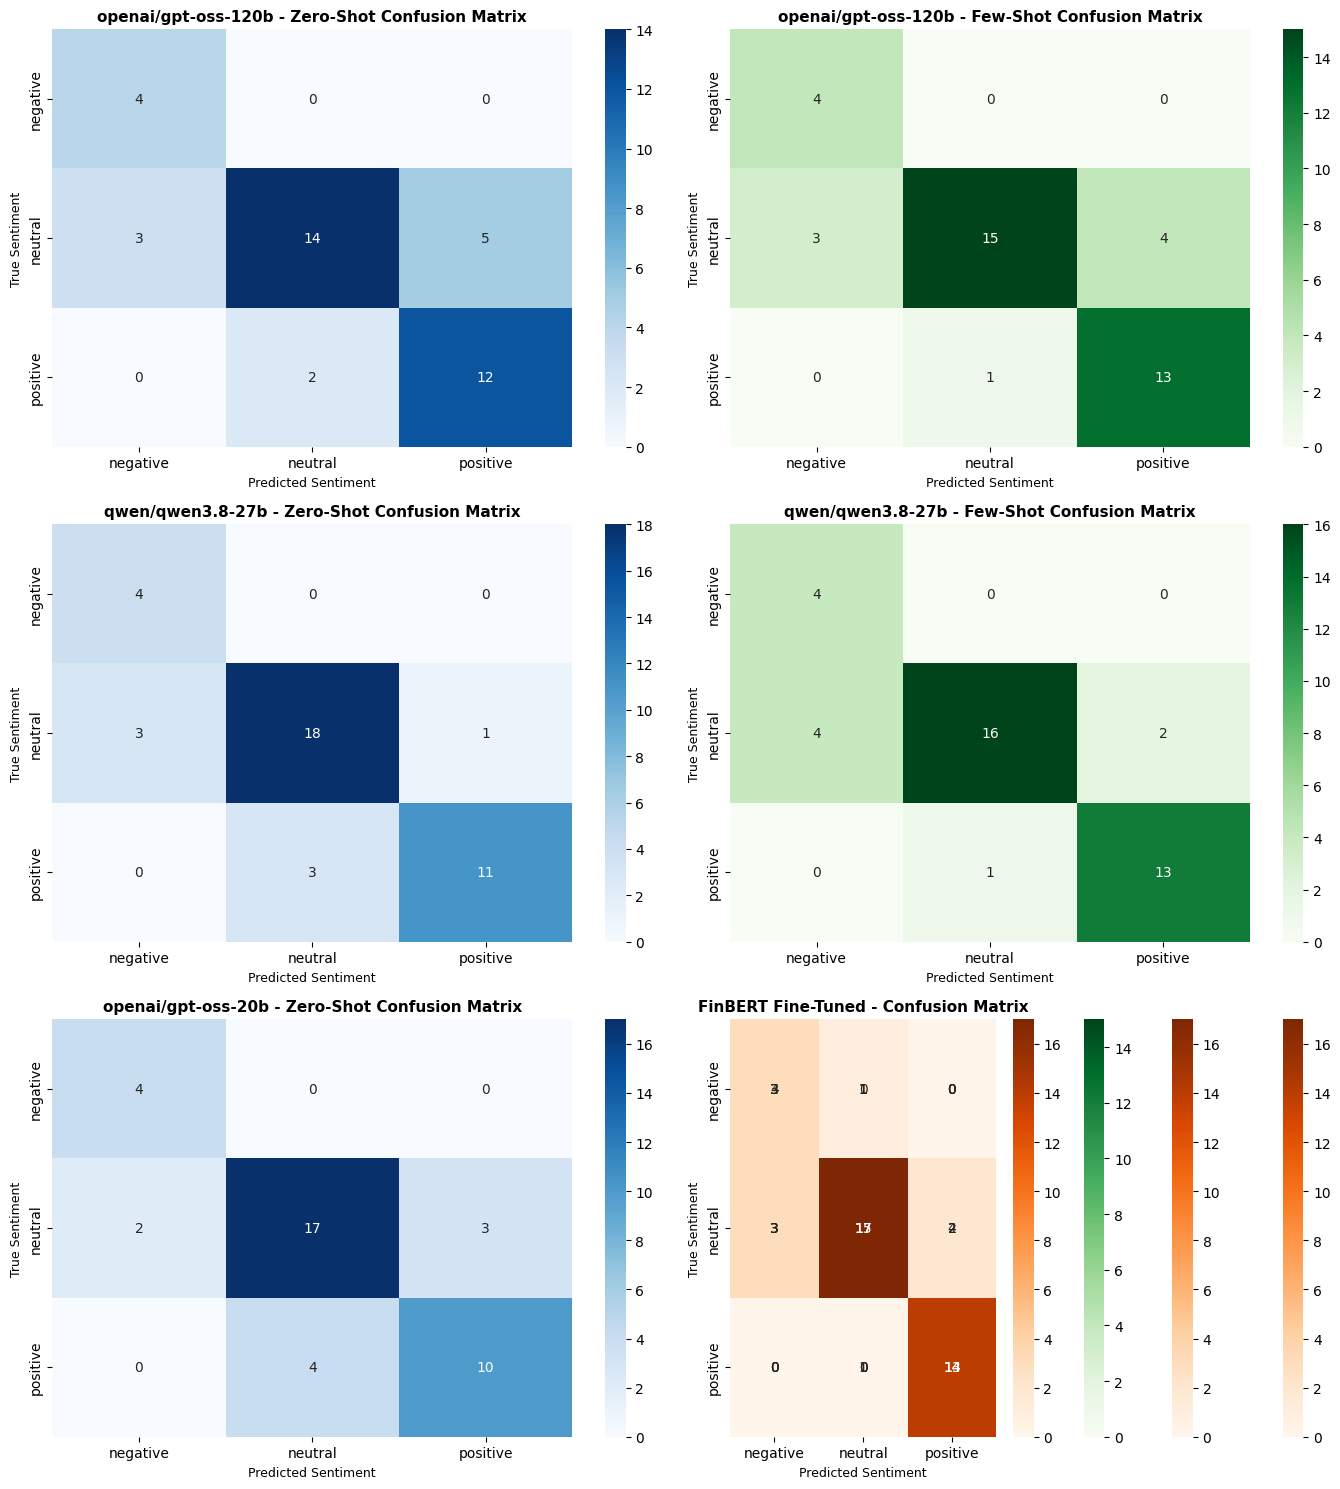

In [20]:
labels = ['negative', 'neutral', 'positive']

fig, axes = plt.subplots(len(MODELS), 2, figsize=(14, 5 * len(MODELS)))
if len(MODELS) == 1:
    axes = np.array([axes])

for idx, model_id in enumerate(MODELS):
    # Zero-shot confusion matrix
    zs_key = f"{model_id}_zs"
    cm_zs = confusion_matrix(true_labels, model_predictions[zs_key], labels=labels)
    sns.heatmap(cm_zs, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels, ax=axes[idx, 0])
    axes[idx, 0].set_title(f"{model_id} - Zero-Shot Confusion Matrix", fontsize=11, fontweight='bold')
    axes[idx, 0].set_xlabel('Predicted Sentiment', fontsize=9)
    axes[idx, 0].set_ylabel('True Sentiment', fontsize=9)

    # Few-shot confusion matrix
    fs_key = f"{model_id}_fs"
    cm_fs = confusion_matrix(true_labels, model_predictions[fs_key], labels=labels)
    sns.heatmap(cm_fs, annot=True, fmt='d', cmap='Greens', xticklabels=labels, yticklabels=labels, ax=axes[idx, 1])
    axes[idx, 1].set_title(f"{model_id} - Few-Shot Confusion Matrix", fontsize=11, fontweight='bold')
    axes[idx, 1].set_xlabel('Predicted Sentiment', fontsize=9)
    axes[idx, 1].set_ylabel('True Sentiment', fontsize=9)

    #  FinBERT Fine-Tuned confusion matrix
    finbert_key = "FinBERT_Fine-Tuned"
    cm_finbert = confusion_matrix(true_labels, model_predictions[finbert_key], labels=labels)
    sns.heatmap(cm_finbert, annot=True, fmt='d', cmap='Oranges', xticklabels=labels, yticklabels=labels, ax=axes[-1, 1])
    axes[-1, 1].set_title(f"FinBERT Fine-Tuned - Confusion Matrix", fontsize=11, fontweight='bold')
    axes[-1, 1].set_xlabel('Predicted Sentiment', fontsize=9)
    axes[-1, 1].set_ylabel('True Sentiment', fontsize=9)

plt.tight_layout()
plt.show()

## **Cell 10: Conclusion and Limitations**

### **Conclusion**
- **Comparative Analysis:** Benchmarking general-purpose LLMs (`openai/gpt-oss-120b`, `qwen/qwen3.8-27b`, `openai/gpt-oss-20b`) against the domain-specific fine-tuned **FinBERT** model highlights the efficacy of task-specific pre-training and fine-tuning on financial corpora.
- **Fine-Tuning Impact:** FinBERT, being pre-trained on a financial corpus and further fine-tuned on the Financial PhraseBank dataset, demonstrates robust domain vocabulary understanding and high classification reliability with low inference latency.
- **Prompt Paradigm Flexibility:** While LLMs require careful prompt tuning or few-shot examples to achieve comparable performance, they offer greater flexibility across diverse textual formats.

### **Limitations**
- **Domain Specialization vs. Generalization:** FinBERT excels in financial sentiment tasks but lacks the broad conversational generalization of large foundation models.
- **API vs. Local Inference:** LLM evaluation via API endpoints introduces rate-limiting and latency constraints compared to local transformer inference.